In [12]:
import numpy as np
import matplotlib.pyplot as plt

import reservoirpy as rpy
from reservoirpy.nodes import Reservoir, Ridge, Input
from reservoirpy.datasets import mackey_glass, to_forecasting, narma, doublescroll
from reservoirpy.observables import rmse, rsquare

rpy.set_seed(42)      # tái lập kết quả

plt.rcParams["figure.dpi"] = 100


## 2. Forecasting Mackey-Glass


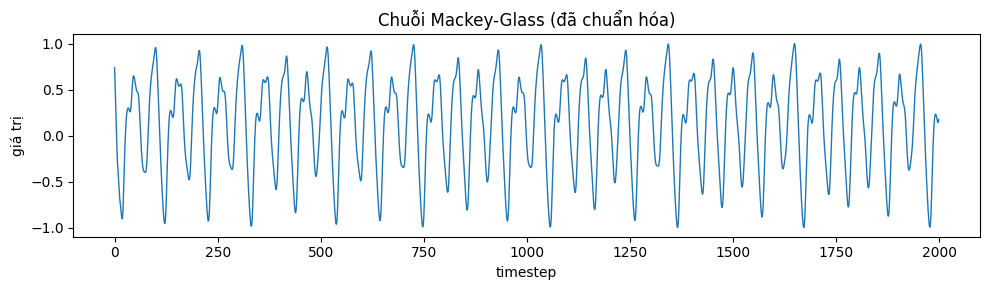

In [13]:
# Sinh 2000 điểm dữ liệu, chuẩn hóa về [-1, 1]
X = mackey_glass(n_timesteps=2000, tau=17)
X = 2 * (X - X.min()) / (X.max() - X.min()) - 1

plt.figure(figsize=(10, 3))
plt.plot(X, lw=1)
plt.title("Chuỗi Mackey-Glass (đã chuẩn hóa)")
plt.xlabel("timestep")
plt.ylabel("giá trị")
plt.tight_layout()
plt.show()


In [14]:
# Chia train/test theo kiểu forecasting: dự báo trước 10 bước (forecast=10)
forecast = 10
x_train, x_test, y_train, y_test = to_forecasting(X, forecast=forecast, test_size=0.2)
print("x_train:", x_train.shape, "| x_test:", x_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)


x_train: (1590, 1) | x_test: (400, 1)
y_train: (1590, 1) | y_test: (400, 1)


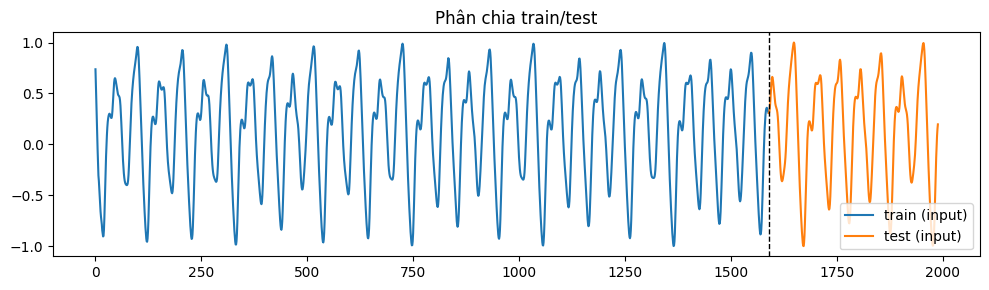

In [15]:
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(x_train)), x_train, label="train (input)")
plt.plot(np.arange(len(x_train), len(x_train) + len(x_test)), x_test, label="test (input)")
plt.axvline(len(x_train), color="k", ls="--", lw=1)
plt.title("Phân chia train/test")
plt.legend()
plt.tight_layout()
plt.show()


### Xây ESN: `Reservoir >> Ridge`

Đây là API cốt lõi của ReservoirPy: nối một `Reservoir` (bể neuron hồi quy phi tuyến, cố
định, không huấn luyện) với một `Ridge` (readout tuyến tính, được huấn luyện bằng hồi quy
Ridge) bằng toán tử `>>`.

In [16]:
reservoir = Reservoir(units=300, sr=0.9, lr=0.3, input_scaling=1.0, seed=42)
readout = Ridge(ridge=1e-7)

model = reservoir >> readout

# warmup: số bước đầu bị bỏ qua để reservoir "quên" trạng thái khởi tạo (transient)
model = model.fit(x_train, y_train, warmup=100)


In [17]:
y_pred = model.run(x_test)

print(f"RMSE  = {rmse(y_test, y_pred):.5f}")
print(f"R^2   = {rsquare(y_test, y_pred):.5f}")


RMSE  = 0.00202
R^2   = 0.99998


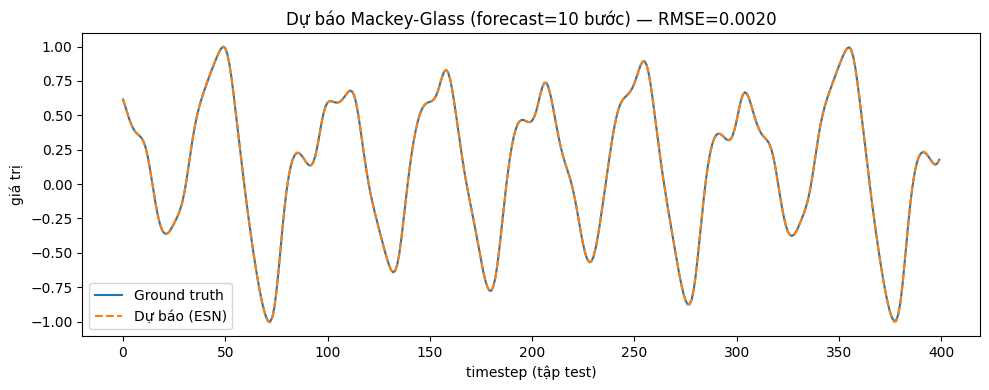

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(y_test, label="Ground truth", lw=1.5)
plt.plot(y_pred, label="Dự báo (ESN)", lw=1.5, ls="--")
plt.title(f"Dự báo Mackey-Glass (forecast={forecast} bước) — RMSE={rmse(y_test, y_pred):.4f}")
plt.xlabel("timestep (tập test)")
plt.ylabel("giá trị")
plt.legend()
plt.tight_layout()
plt.show()


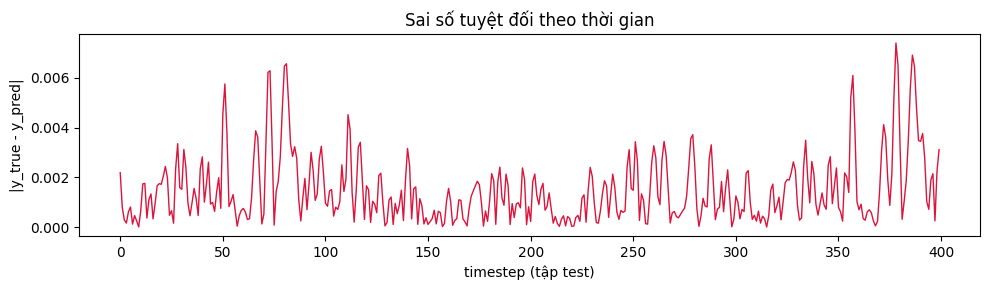

In [19]:
error = np.abs(y_test - y_pred)
plt.figure(figsize=(10, 3))
plt.plot(error, color="crimson", lw=1)
plt.title("Sai số tuyệt đối theo thời gian")
plt.xlabel("timestep (tập test)")
plt.ylabel("|y_true - y_pred|")
plt.tight_layout()
plt.show()


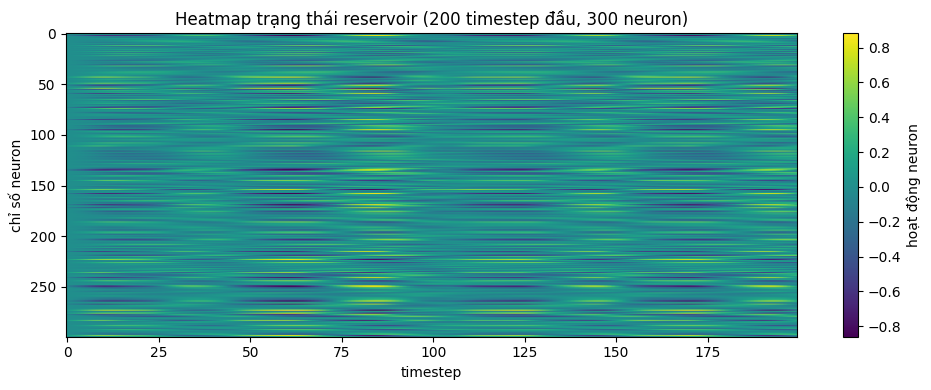

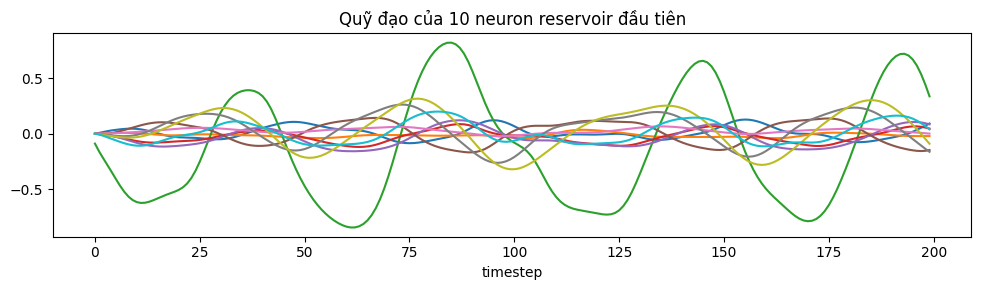

In [20]:
reservoir.reset()  # reset trạng thái nội tại về 0 trước khi quan sát
states = reservoir.run(x_test)   # (timesteps, units)

plt.figure(figsize=(10, 4))
plt.imshow(states[:200].T, aspect="auto", cmap="viridis")
plt.colorbar(label="hoạt động neuron")
plt.title("Heatmap trạng thái reservoir (200 timestep đầu, 300 neuron)")
plt.xlabel("timestep")
plt.ylabel("chỉ số neuron")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(states[:200, :10])
plt.title("Quỹ đạo của 10 neuron reservoir đầu tiên")
plt.xlabel("timestep")
plt.tight_layout()
plt.show()


## 3. NARMA-30: non-linear detection



u (input): (2030, 1) -> aligned: (2000, 1)
y (target): (2000, 1)


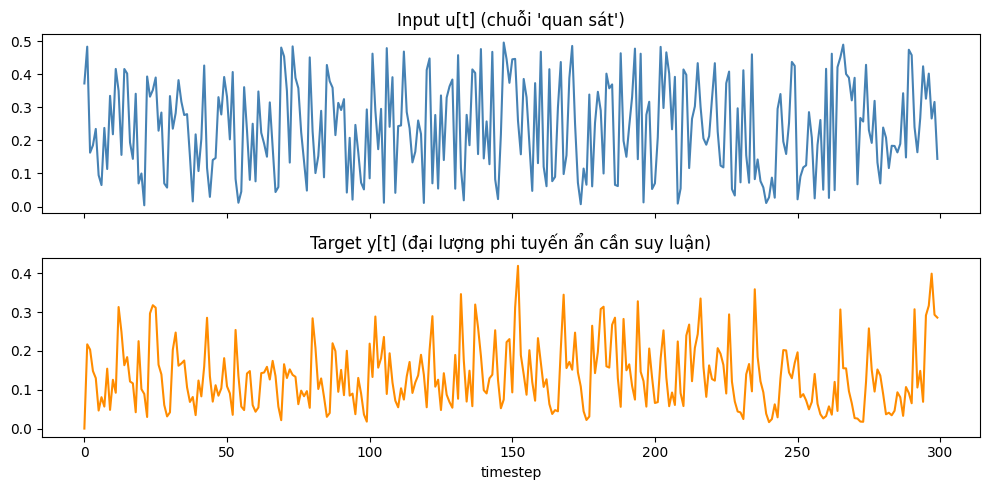

In [21]:
n_timesteps, order = 2000, 30
u, y = narma(n_timesteps=n_timesteps, order=order, seed=42)

# u có độ dài n_timesteps + order (cần lịch sử để tính y[0]); căn chỉnh lại cho khớp y
u_aligned = u[order:]

print("u (input):", u.shape, "-> aligned:", u_aligned.shape)
print("y (target):", y.shape)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(u_aligned[:300], color="steelblue")
axes[0].set_title("Input u[t] (chuỗi 'quan sát')")
axes[1].plot(y[:300], color="darkorange")
axes[1].set_title("Target y[t] (đại lượng phi tuyến ẩn cần suy luận)")
axes[1].set_xlabel("timestep")
plt.tight_layout()
plt.show()


In [22]:
narma_test_size = 400
u_train, u_test = u_aligned[:-narma_test_size], u_aligned[-narma_test_size:]
y_train_n, y_test_n = y[:-narma_test_size], y[-narma_test_size:]

reservoir_n = Reservoir(units=200, sr=0.95, lr=1.0, seed=42)
readout_n = Ridge(ridge=1e-6)
model_n = reservoir_n >> readout_n

model_n = model_n.fit(u_train, y_train_n, warmup=30)
y_pred_n = model_n.run(u_test)

print(f"NARMA-30 RMSE = {rmse(y_test_n, y_pred_n):.5f}")
print(f"NARMA-30 R^2  = {rsquare(y_test_n, y_pred_n):.5f}")


NARMA-30 RMSE = 0.06256
NARMA-30 R^2  = 0.51207


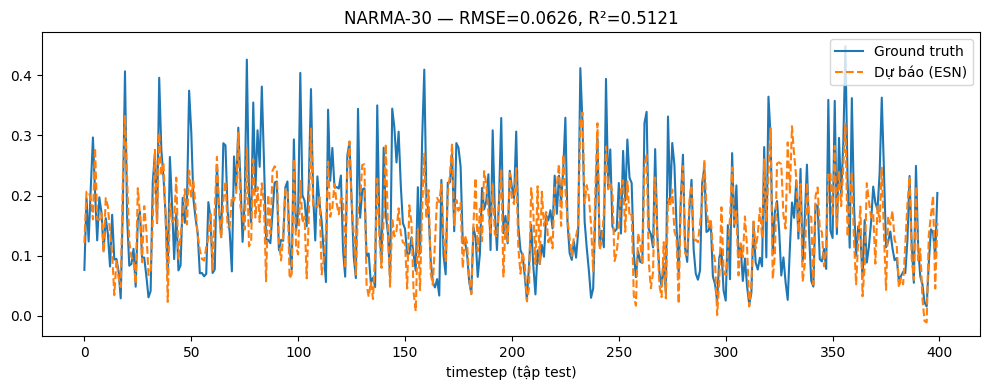

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(y_test_n, label="Ground truth", lw=1.5)
plt.plot(y_pred_n, label="Dự báo (ESN)", lw=1.5, ls="--")
plt.title(f"NARMA-30 — RMSE={rmse(y_test_n, y_pred_n):.4f}, R²={rsquare(y_test_n, y_pred_n):.4f}")
plt.xlabel("timestep (tập test)")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Phần C — Quét hyperparameter (`sr`, `lr`)

Hai hyperparameter quan trọng nhất của `Reservoir` là:
- `sr` (spectral radius): kiểm soát mức độ "hỗn loạn"/độ nhớ dài của động lực học nội tại.
- `lr` (leaking rate): kiểm soát tốc độ cập nhật trạng thái (bộ nhớ ngắn hạn).

Việc quét lưới (grid search) đơn giản này minh họa cách bạn có thể tối ưu các
hyperparameter tương ứng khi chuyển sang bài toán thật (vd. tối ưu cho tín hiệu
entanglement monitoring của bạn, có thể qua `reservoirpy.hyper` với hyperopt).


In [24]:
sr_values = [0.5, 0.8, 0.9, 0.99, 1.1, 1.3]
lr_values = [0.1, 0.3, 0.5, 0.7, 1.0]

results = np.zeros((len(sr_values), len(lr_values)))

for i, sr in enumerate(sr_values):
    for j, lr in enumerate(lr_values):
        res = Reservoir(units=200, sr=sr, lr=lr, seed=42)
        ro = Ridge(ridge=1e-7)
        m = res >> ro
        m = m.fit(x_train, y_train, warmup=100)
        pred = m.run(x_test)
        results[i, j] = rmse(y_test, pred)

print("Hoàn tất grid search.")


Hoàn tất grid search.


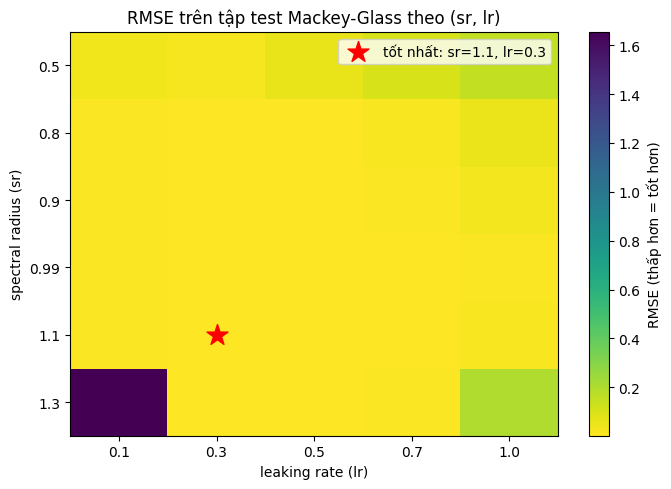

Cấu hình tốt nhất: sr=1.1, lr=0.3, RMSE=0.00143


In [25]:
plt.figure(figsize=(7, 5))
plt.imshow(results, cmap="viridis_r", aspect="auto")
plt.colorbar(label="RMSE (thấp hơn = tốt hơn)")
plt.xticks(range(len(lr_values)), lr_values)
plt.yticks(range(len(sr_values)), sr_values)
plt.xlabel("leaking rate (lr)")
plt.ylabel("spectral radius (sr)")
plt.title("RMSE trên tập test Mackey-Glass theo (sr, lr)")

best_i, best_j = np.unravel_index(np.argmin(results), results.shape)
plt.scatter([best_j], [best_i], marker="*", s=250, color="red",
            label=f"tốt nhất: sr={sr_values[best_i]}, lr={lr_values[best_j]}")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Cấu hình tốt nhất: sr={sr_values[best_i]}, lr={lr_values[best_j]}, "
      f"RMSE={results[best_i, best_j]:.5f}")


## 5. Double-scroll attractor


c:\Users\binh1\miniconda3\envs\py3.10_pytorch\lib\site-packages\reservoirpy\datasets\_chaos.py:528: RuntimeWarning: overflow encountered in sinh
  factor = (dV / r2) + ir * np.sinh(beta * dV)
c:\Users\binh1\miniconda3\envs\py3.10_pytorch\lib\site-packages\reservoirpy\datasets\_chaos.py:529: RuntimeWarning: invalid value encountered in scalar subtract
  dV1 = (V1 / r1) - factor
c:\Users\binh1\miniconda3\envs\py3.10_pytorch\lib\site-packages\scipy\integrate\_ivp\rk.py:109: RuntimeWarning: invalid value encountered in divide
  return norm(self._estimate_error(K, h) / scale)


Shape: (3000, 3)


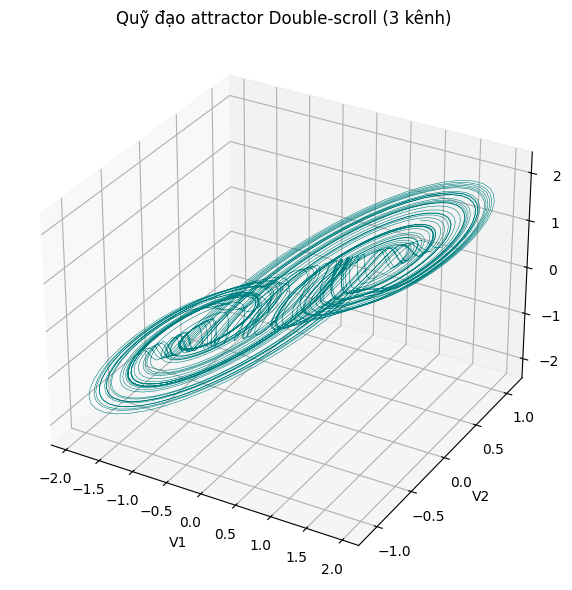

In [26]:
X3 = doublescroll(n_timesteps=3000)
print("Shape:", X3.shape)  # (timesteps, 3)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(X3[:, 0], X3[:, 1], X3[:, 2], lw=0.4, color="teal")
ax.set_title("Quỹ đạo attractor Double-scroll (3 kênh)")
ax.set_xlabel("V1"); ax.set_ylabel("V2"); ax.set_zlabel("I")
plt.tight_layout()
plt.show()


In [27]:
# Chuẩn hóa từng kênh, rồi dự báo trước 5 bước cho cả 3 kênh cùng lúc
X3n = (X3 - X3.mean(axis=0)) / X3.std(axis=0)

x3_train, x3_test, y3_train, y3_test = to_forecasting(X3n, forecast=5, test_size=0.2)

reservoir3 = Reservoir(units=400, sr=1.0, lr=0.4, seed=42)
readout3 = Ridge(ridge=1e-6)
model3 = reservoir3 >> readout3
model3 = model3.fit(x3_train, y3_train, warmup=100)
y3_pred = model3.run(x3_test)

print(f"RMSE trung bình 3 kênh = {rmse(y3_test, y3_pred):.5f}")


RMSE trung bình 3 kênh = 0.01040


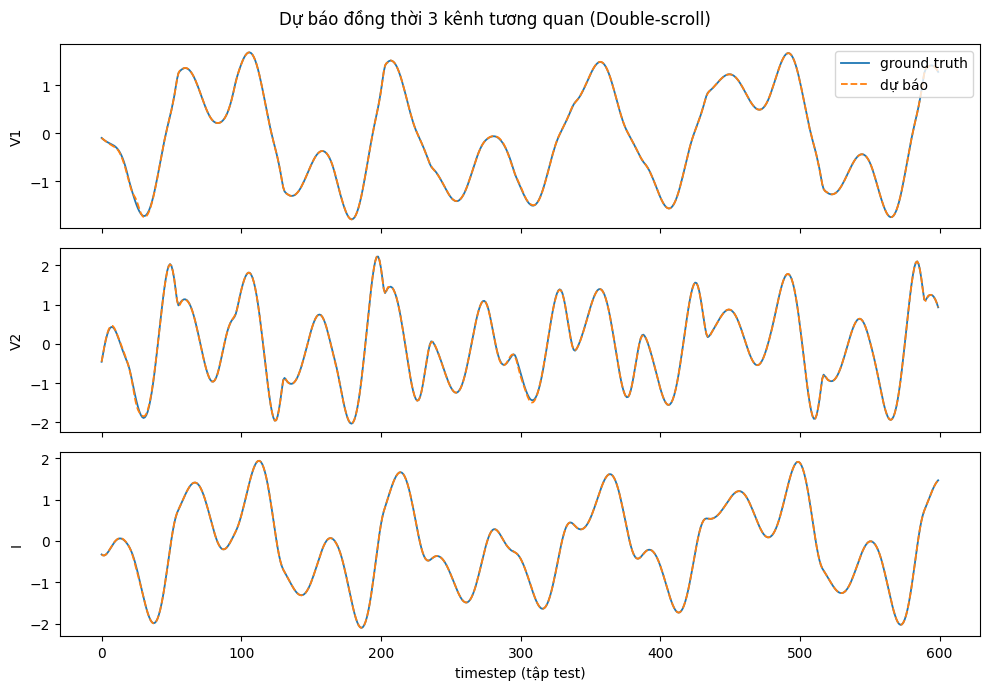

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
labels = ["V1", "V2", "I"]
for k in range(3):
    axes[k].plot(y3_test[:, k], label="ground truth", lw=1.3)
    axes[k].plot(y3_pred[:, k], label="dự báo", lw=1.3, ls="--")
    axes[k].set_ylabel(labels[k])
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("timestep (tập test)")
fig.suptitle("Dự báo đồng thời 3 kênh tương quan (Double-scroll)")
plt.tight_layout()
plt.show()


## 6. Từ đây sang bài toán entanglement monitoring thực tế

Để chuyển pipeline này sang bài toán của bạn (giám sát entanglement của flying qubit từ
tín hiệu đo lường OAM/polarization), về cơ bản chỉ cần thay hai điểm:

1. **Nguồn dữ liệu**: thay `mackey_glass(...)` / `narma(...)` bằng dữ liệu bạn tự sinh —
   ví dụ chuỗi kết quả đo lường (single-shot outcomes, fidelity theo thời gian) từ mô
   phỏng NetSquid, hoặc từ dữ liệu QELM/photonic thực nghiệm. Miễn dữ liệu ở dạng
   `(timesteps, features)` là ghép được ngay vào pipeline `Reservoir >> Ridge` ở trên.
2. **Nhãn cần học (`y`)**: thay vì dự báo giá trị tương lai của chính tín hiệu, `y` của
   bạn sẽ là entanglement witness / concurrence / negativity ứng với mỗi thời điểm — tức
   là bài toán *regression giữa trạng thái reservoir và một đại lượng vật lý ẩn*, đúng
   cấu trúc như Phần B (NARMA) ở trên chứ không phải forecasting thuần như Phần A.

Phần readout (`Ridge`), warmup, và cách đánh giá (`rmse`, `rsquare`) giữ nguyên. Phần
`Reservoir` cổ điển (mạng neuron hồi quy thực) có thể giữ làm baseline so sánh với
reservoir lượng tử (QELM) mà bạn tự cài đặt riêng (dùng Qiskit/PennyLane/QuTiP), miễn là
lớp đó cũng xuất ra một vector trạng thái `(timesteps, dims)` để đưa vào `Ridge`.
